# Chapitre 17 - Modèles graphiques non orientés
## Cours 2 : variables binaires - modèles de Ising et machines de Boltzmann

Ce notebook couvre la section 17.4 du livre : les graphes de Markov par paires dont
les sommets sont des variables **binaires** $X_j \in \{0, 1\}$. Ces modèles s'appellent
**modèles de Ising** en physique statistique et **machines de Boltzmann** en
apprentissage automatique (les sommets y sont des « unités »).

Plan :

1. le modèle de Ising, la fonction de partition et le nœud constant $X_0 \equiv 1$ ;
2. les lois conditionnelles logistiques et l'interprétation des paramètres ;
3. le maximum de vraisemblance : égalisation des moments, Newton et IPF par
   **énumération** des $2^p$ états (petit $p$) ;
4. quand $p$ est grand : échantillonnage de Gibbs, champ moyen, **pseudo-vraisemblance**
   et régressions logistiques $\ell_1$ nœud par nœud (estimation du graphe) ;
5. les nœuds cachés et les **machines de Boltzmann restreintes** (RBM), avec un exemple
   sur les chiffres manuscrits.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

## 1. Le modèle de Ising

Soit $G = (V, E)$ un graphe sur $p$ sommets et $X = (X_1, \dots, X_p) \in \mathcal X = \{0,1\}^p$.
Le modèle de Ising définit la loi jointe (éq. (17.28)–(17.29) du livre)

$$
p(x, \Theta) = \exp\Big[\sum_{(j,k)\in E}\theta_{jk}x_jx_k - \Phi(\Theta)\Big],
\qquad
\Phi(\Theta) = \log\sum_{x\in\mathcal X}\exp\Big[\sum_{(j,k)\in E}\theta_{jk}x_jx_k\Big].
$$

$\Phi$ est le **logarithme de la fonction de partition** : il assure que les $2^p$
probabilités somment à 1. Seules des interactions **par paires** sont modélisées : c'est
un graphe de Markov par paires, avec le potentiel $\psi_{jk}(x_j, x_k) = e^{\theta_{jk}x_jx_k}$
sur chaque arête.

**Le nœud constant.** Pour des raisons techniques (exercice 17.10), on ajoute un nœud
$X_0 \equiv 1$ relié à tous les autres : le terme $\theta_{j0}x_jx_0 = \theta_{j0}x_j$ joue
le rôle d'un effet principal (une « ordonnée à l'origine » propre à chaque variable).
Sans lui, le modèle à $\Theta = 0$ serait forcément la loi uniforme, et les marges ne
pourraient pas être ajustées librement. Nous écrivons donc

$$
\log p(x) = \sum_{j=1}^p \theta_{j0}x_j + \sum_{j<k}\theta_{jk}x_jx_k - \Phi(\Theta),
$$

avec $\theta_{jk} = 0$ si $(j,k)\notin E$. Dans le code, `theta0` est le vecteur des
$\theta_{j0}$ et `Theta` la matrice symétrique des $\theta_{jk}$ (diagonale nulle).

> **Remarque.** Le modèle est une **famille exponentielle** : $\log p(x)$ est linéaire en
> les paramètres, multipliés par les **statistiques suffisantes** $t(x) = (x_j, x_jx_k)$.
> C'est aussi un modèle log-linéaire « d'interactions du premier ordre » pour la table de
> contingence à $2^p$ cases (exercice 17.12).

Pour un petit $p$ on peut tout calculer en énumérant les $2^p$ états. Exemple : le
cycle à 4 sommets, avec des interactions toutes positives (« attraction » : les
variables aiment prendre la même valeur) ou toutes négatives (« répulsion »).

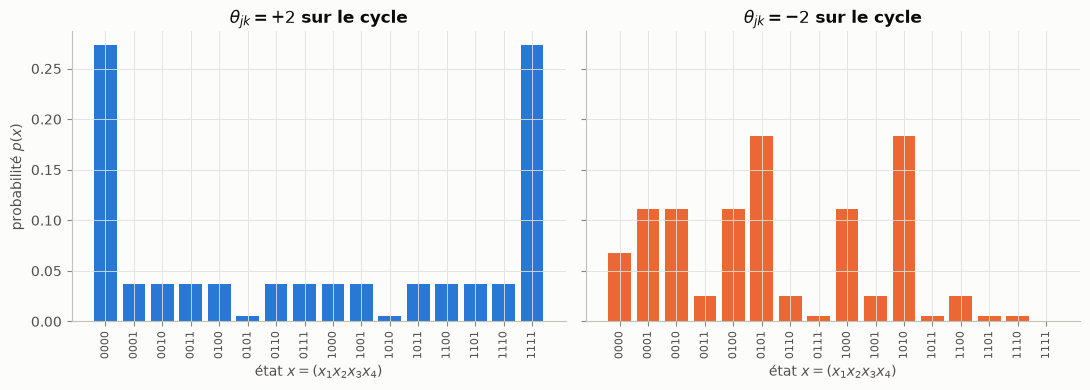

In [2]:
p4 = 4
A_cycle = g.adjacency_from_edges(p4, [(0, 1), (1, 2), (2, 3), (3, 0)])
etats4 = g.ising_states(p4)
etiq = ["".join(str(int(v)) for v in x) for x in etats4]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, signe, col in [(axes[0], +1, BLUE), (axes[1], -1, ORANGE)]:
    Th = 2.0 * signe * A_cycle
    theta0_4 = np.full(p4, -2.0 if signe > 0 else 0.5)
    _, pr = g.ising_probs(theta0_4, Th)
    ax.bar(range(16), pr, color=col)
    ax.set_xticks(range(16), etiq, rotation=90, fontsize=8)
    ax.set(xlabel="état $x = (x_1 x_2 x_3 x_4)$",
           title=r"$\theta_{jk} = %+d$ sur le cycle" % (2 * signe))
axes[0].set_ylabel("probabilité $p(x)$")
plt.tight_layout()
plt.show()

Avec des couplages positifs (et $\theta_{j0} = -2$), les états « tout à 0 » et « tout
à 1 » dominent : les variables s'alignent. Avec des couplages négatifs (et
$\theta_{j0} = +0{,}5$), les états alternés $1010$ et $0101$, où deux voisins sont
toujours différents, sont les plus probables.

## 2. Lois conditionnelles logistiques

Fixons toutes les variables sauf $X_j$ et notons $x_{-j}$ leurs valeurs. Dans le rapport
$p(x_j = 1, x_{-j}) / p(x_j = 0, x_{-j})$, la constante $\Phi$ et tous les termes ne
contenant pas $x_j$ se simplifient ; il reste

$$
\frac{\Pr(X_j = 1 \mid x_{-j})}{\Pr(X_j = 0 \mid x_{-j})}
= \exp\Big(\theta_{j0} + \sum_{k:(j,k)\in E}\theta_{jk}x_k\Big),
$$

donc (éq. (17.30), démontrée en détail dans l'exercice 17.11)

$$
\Pr(X_j = 1 \mid X_{-j} = x_{-j}) = \frac{1}{1 + \exp\big(-\theta_{j0} - \sum_{(j,k)\in E}\theta_{jk}x_k\big)} .
$$

Chaque nœud suit une **régression logistique** sur ses voisins. En particulier, la loi
de $X_j$ sachant le reste ne dépend que des voisins de $j$ : c'est la propriété de
Markov.

**Interprétation de $\theta_{jk}$.** En prenant la différence des log-cotes entre
$x_k = 1$ et $x_k = 0$ (les autres variables fixées) :

$$
\theta_{jk} = \log\frac{\Pr(X_j=1\mid x_k=1,\cdot)/\Pr(X_j=0\mid x_k=1,\cdot)}{\Pr(X_j=1\mid x_k=0,\cdot)/\Pr(X_j=0\mid x_k=0,\cdot)},
$$

le **log-rapport de cotes conditionnel** entre $X_j$ et $X_k$. Vérifions la formule
logistique et l'indépendance $X_1 \perp X_3 \mid (X_2, X_4)$ sur le cycle.

In [ ]:
rng = np.random.RandomState(0)
Th4 = np.zeros((p4, p4))
for j, k in g.edges_from_adjacency(A_cycle):
    Th4[j, k] = Th4[k, j] = rng.uniform(-2, 2)
th0 = rng.uniform(-1, 1, p4)
X4, pr4 = g.ising_probs(th0, Th4)
P = pr4.reshape(2, 2, 2, 2)  # P[x1, x2, x3, x4]

# Pr(X1 = 1 | x2, x3, x4) par la définition, puis par la formule logistique
cond_def = P[1] / P.sum(axis=0)
cond_log = g.ising_conditional(X4[X4[:, 0] == 1], 0, th0, Th4).reshape(2, 2, 2)
print("écart max définition / logistique : %.1e" % np.abs(cond_def - cond_log).max())
print("Pr(X1=1 | x2, x3, x4) ne dépend pas de x3 :",
      np.allclose(cond_def[:, 0, :], cond_def[:, 1, :]))

## 3. Maximum de vraisemblance (graphe connu)

Soient $x_1, \dots, x_N \in \{0,1\}^p$ des observations i.i.d. La log-vraisemblance est
(éq. (17.31))

$$
\ell(\Theta) = \sum_{i=1}^N\Big[\sum_{(j,k)\in E}\theta_{jk}x_{ij}x_{ik} - \Phi(\Theta)\Big]
$$

(les arêtes vers $X_0$ incluses). Sa dérivée partielle est (éq. (17.32))

$$
\frac{\partial\ell}{\partial\theta_{jk}} = \sum_{i=1}^N x_{ij}x_{ik} - N\frac{\partial\Phi}{\partial\theta_{jk}} .
$$

**Dérivée de $\Phi$.** Par dérivation d'un logarithme puis d'une exponentielle :

$$
\frac{\partial\Phi}{\partial\theta_{jk}}
= \frac{\sum_x x_jx_k\, e^{\sum\theta x x}}{\sum_x e^{\sum\theta x x}}
= \sum_{x\in\mathcal X}x_jx_k\,p(x,\Theta) = \mathrm E_\Theta(X_jX_k) \qquad\text{(éq. (17.33))}.
$$

L'équation de vraisemblance est donc (éq. (17.34)–(17.35))

$$
\hat{\mathrm E}(X_jX_k) - \mathrm E_\Theta(X_jX_k) = 0,
\qquad \hat{\mathrm E}(X_jX_k) = \frac1N\sum_{i=1}^N x_{ij}x_{ik} .
$$

> **À retenir.** Le maximum de vraisemblance **égalise les moments** : les produits
> croisés attendus sous le modèle doivent coïncider avec les produits croisés observés
> (forme générale des équations de score dans une famille exponentielle).